# Jay: a tiny ChatGPT built from scratch

A 12.3M-parameter chat assistant trained from zero with PyTorch on a free Colab GPU, following the stages in Andrej Karpathy's [*Deep Dive into LLMs like ChatGPT*](https://www.youtube.com/watch?v=7xTGNNLPyMI):

1. **Data and tokenization** (Steps 1–7): TinyStories and a 4,096-token BPE tokenizer.
2. **The model** (Steps 8–15): a GPT-style Transformer written by hand.
3. **Pretraining** (Steps 16–25): next-token prediction, then exploring the base model.
4. **Supervised fine-tuning** (Steps 26–37): conversations, loss masking and evaluation.
5. **"I don't know"** (Steps 38–39): reducing hallucinations.
6. **Reinforcement learning, simplified** (Steps 40–45): rejection sampling on reworded math questions.

Runtime: *Runtime → Change runtime type → T4 GPU*, then run the steps in order.

## Step 1: Installing libraries

Install the `tokenizers` library (fast BPE training) and `tiktoken` (to look at the GPT-4 tokenizer).

In [1]:
# STEP 1: INSTALLING LIBRARIES
!pip install -q tokenizers tiktoken

## Step 2a: Imports and GPU check

Import PyTorch and check whether a GPU is available.

In [3]:
# STEP 2a: IMPORTS AND GPU CHECK
import math, os, random, time, urllib.request
import torch
import torch.nn as nn
import torch.nn.functional as F

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Running on: {device}")
if device == "cuda":
  print(f"GPU: {torch.cuda.get_device_name(0)}")

Running on: cpu


## Step 2b: Hyperparameters

All the settings in one place: the model size (6 layers, 6 heads, 384-dim embeddings, 256-token context) and the training lengths and learning rates.

In [4]:
# STEP 2b: CONFIGURING HYPERPARAMETERS
# --- Model size ---
VOCAB_SIZE = 4096 # number of different tokens our model knows
BLOCK_SIZE = 256  # context window: how many tokens the model sees at once
N_LAYER    = 6    # number of Transformer blocks stacked
N_HEAD     = 6    # number of attention "heads" per block
N_EMBD     = 384  # size of each token's vector; must be divisible by N_HEAD (384/6 = 64 per head)
DROPOUT    = 0.1  # randomly turns off 10% of neurons during training

# --- Training size ---
BATCH_SIZE    = 32
PRETRAIN_STEPS = 3000
PRETRAIN_LR   = 1e-3
SFT_STEPS     = 1500
SFT_LR        = 2e-4

torch.manual_seed(1337)
random.seed(1337)

## Step 2c: Downloading the data

Download TinyStories (~19 MB of short children's stories) and split the file into individual stories.

In [4]:
# STEP 2c: DOWNLOADING THE DATA
DATA_URL = "https://huggingface.co/datasets/roneneldan/TinyStories/resolve/main/TinyStories-valid.txt"
DATA_FILE = "tinystories.txt"

if not os.path.exists(DATA_FILE):
  print("Downloading TinyStories (~19MB)...")
  urllib.request.urlretrieve(DATA_URL, DATA_FILE)

with open(DATA_FILE, encoding="utf-8") as f:
  raw_text = f.read()

stories = [s.strip() for s in raw_text.split("<|endoftext|>") if s.strip()]

print(f"Number of stories: {len(stories):,}")
print(f"Number of characters: {len(raw_text):,}")
print("\n--- Example story ---\n")
print(stories[0])

# Show a random story and the total number of words
print(random.choice(stories))
print(sum(len(s.split()) for s in stories))

Number of stories: 21,990
Number of characters: 19,432,979

--- Example story ---

Spot. Spot saw the shiny car and said, "Wow, Kitty, your car is so bright and clean!" Kitty smiled and replied, "Thank you, Spot. I polish it every day."
After playing with the car, Kitty and Spot felt thirsty. They found a small pond with clear water. They drank the water and felt very happy. They played together all day and became best friends.
Once upon a time, there was a little boy named Tim. Tim loved to play with his toy train. The train had a long rail that Tim could put together. He was very happy when he played with his train.
One day, Tim wanted to pour water on the rail to make it slippery for the train. He thought it would be fun to watch the train go fast. But it was a stupid idea because the train could not go on the wet rail. The train slipped and fell off the rail.
Tim was sad that his train fell off the rail. He learned that pouring water on the rail was not a good idea. Next time, he d

## Step 3: Byte Pair Encoding (BPE) by hand

A from-scratch BPE on a toy sentence: repeatedly find the most common pair of tokens and merge it into a new token.

In [ ]:
# STEP 3: BYTE PAIR ENCODING (BPE)
def most_common_pair(ids):
  counts = {}
  for a, b in zip(ids, ids[1:]):
    counts[(a, b)] = counts.get((a, b), 0) + 1
  best = max(counts, key=counts.get)
  return best, counts[best]

def merge(ids, pair, new_id):
  out, i = [], 0
  while i < len(ids):
    if i< len(ids) - 1 and (ids[i], ids[i + 1]) == pair:
      out.append(new_id)
      i += 2   # skip past both merged tokens
    else:
      out.append(ids[i])
      i += 1
  return out

text = "the cat and the hat and the bat"
ids = list(text.encode("utf-8"))
print(f"Start: {len(ids)} tokens -> {ids}\n")

vocab = {i: bytes([i]).decode("latin-1") for i in range(256)}
for k in range(6):
  pair, count = most_common_pair(ids)
  new_id = 256 + k
  ids = merge(ids, pair, new_id)
  vocab[new_id] = vocab[pair[0]] + vocab[pair[1]]
  print(f"Merge {k+1}: '{vocab[pair[0]]}' + '{vocab[pair[1]]}' -> '{vocab[new_id]}' "
          f"(new id {new_id}, seen {count}x) | length: {len(ids)}")

print(f"\nEnd: {len(ids)} tokens -> {ids}")
print("As pieces:", [vocab[i] for i in ids])

Start: 31 tokens -> [116, 104, 101, 32, 99, 97, 116, 32, 97, 110, 100, 32, 116, 104, 101, 32, 104, 97, 116, 32, 97, 110, 100, 32, 116, 104, 101, 32, 98, 97, 116]

Merge 1: 't' + 'h' -> 'th' (new id 256, seen 3x) | length: 28
Merge 2: 'th' + 'e' -> 'the' (new id 257, seen 3x) | length: 25
Merge 3: 'the' + ' ' -> 'the ' (new id 258, seen 3x) | length: 22
Merge 4: 'a' + 't' -> 'at' (new id 259, seen 3x) | length: 19
Merge 5: 'at' + ' ' -> 'at ' (new id 260, seen 2x) | length: 17
Merge 6: 'at ' + 'a' -> 'at a' (new id 261, seen 2x) | length: 15

End: 15 tokens -> [258, 99, 261, 110, 100, 32, 258, 104, 261, 110, 100, 32, 258, 98, 259]
As pieces: ['the ', 'c', 'at a', 'n', 'd', ' ', 'the ', 'h', 'at a', 'n', 'd', ' ', 'the ', 'b', 'at']


## Step 4: The GPT-4 tokenizer

Compare with a real production tokenizer (`cl100k_base`) to see how capitalisation and spacing change the tokens.

In [ ]:
# STEP 4: GPT-4 TOKENIZER
import tiktoken

enc = tiktoken.get_encoding("cl100k_base") # The GPT-4 tokenizer

for sample in ["Hello world!", "hello world!", "HELLO WORLD!", "Tokenization is weird."]:
  ids = enc.encode(sample)
  pieces = [enc.decode([i]) for i in ids]
  print(f"{sample!r:28} -> {len(ids)} tokens: {ids}  {pieces}")

print(f"\nGPT-4 vocabulary size: {enc.n_vocab:,}")

'Hello world!'               -> 3 tokens: [9906, 1917, 0]  ['Hello', ' world', '!']
'hello world!'               -> 3 tokens: [15339, 1917, 0]  ['hello', ' world', '!']
'HELLO WORLD!'               -> 4 tokens: [51812, 1623, 51991, 0]  ['HEL', 'LO', ' WORLD', '!']
'Tokenization is weird.'     -> 5 tokens: [3404, 2065, 374, 16682, 13]  ['Token', 'ization', ' is', ' weird', '.']

GPT-4 vocabulary size: 100,277


## Step 5: Training a tokenizer on TinyStories

Train a 4,096-token byte-level BPE tokenizer on the stories, with 4 special tokens reserved for chat. Round-trip a sentence and save the tokenizer.

In [ ]:
# STEP 5: TRAINING A TOKENIZER ON TINYSTORIES
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

# 'stories' is created in STEP 2c
if "stories" not in globals():
    raise RuntimeError("'stories' doesn't exist yet -> run STEP 2c (Downloading the data) first, then re-run this cell.")

# Special tokens = reserved "tags" the model will later use for chat (user / assistant turns)
SPECIAL_TOKENS = ["<|endoftext|>", "<|user|>", "<|assistant|>", "<|end|>"]

tokenizer = Tokenizer(models.BPE())                                          # same BPE idea as STEP 3, but fast (written in Rust)
tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)   # works on raw bytes -> never meets an "unknown" character
tokenizer.decoder = decoders.ByteLevel()                                     # turns bytes back into readable text

trainer = trainers.BpeTrainer(
    vocab_size=VOCAB_SIZE,                               # 4096 tokens, set in STEP 2b
    special_tokens=SPECIAL_TOKENS,
    initial_alphabet=pre_tokenizers.ByteLevel.alphabet() # start from all 256 bytes, like STEP 3
)

tokenizer.train_from_iterator(stories, trainer=trainer)
print("Vocabulary size:", tokenizer.get_vocab_size())

# Quick test: encode a sentence, look at the pieces, then decode it back
sample = "Once upon a time, there was a little cat."
encoded = tokenizer.encode(sample)
print(f"\n{sample!r} -> {len(encoded.ids)} tokens")
print("IDs:   ", encoded.ids)
print("Pieces:", encoded.tokens)
print("Decoded back:", tokenizer.decode(encoded.ids))
assert tokenizer.decode(encoded.ids) == sample, "Round-trip failed!"

# Special-token IDs we'll need later for chat fine-tuning (SFT)
for t in SPECIAL_TOKENS:
    print(f"{t:16} -> id {tokenizer.token_to_id(t)}")

# Save it so we don't have to retrain after a restart
tokenizer.save("tinystories_tokenizer.json")
print("\nSaved to tinystories_tokenizer.json")

Vocabulary size: 4096

'Once upon a time, there was a little cat.' -> 11 tokens
IDs:    [425, 441, 262, 391, 15, 394, 283, 262, 393, 706, 17]
Pieces: ['Once', 'Ġupon', 'Ġa', 'Ġtime', ',', 'Ġthere', 'Ġwas', 'Ġa', 'Ġlittle', 'Ġcat', '.']
Decoded back: Once upon a time, there was a little cat.
<|endoftext|>    -> id 0
<|user|>         -> id 1
<|assistant|>    -> id 2
<|end|>          -> id 3

Saved to tinystories_tokenizer.json


## Step 6: Encode and decode

Helper functions to turn text into token ids and back, plus a look at how rare words get split into pieces.

In [ ]:
# STEP 6: ENCODE AND DECODE
EOT       = tokenizer.token_to_id("<|endoftext|>")
USER      = tokenizer.token_to_id("<|user|>")
ASSISTANT = tokenizer.token_to_id("<|assistant|>")
END       = tokenizer.token_to_id("<|end|>")
print("Special token ids:", EOT, USER, ASSISTANT, END)

def encode(text):
  return tokenizer.encode(text).ids

def decode(ids):
  return tokenizer.decode(ids, skip_special_tokens=False)

example = "Once upon a time, there was a little dog named Max"
ids = encode(example)
print("\nText   :", example)
print("\nTokens   :", ids)
print("\nPieces   :", [tokenizer.id_to_token(i) for i in ids])
print("\nDecoded   :", decode(ids))
print(f"{len(example)} characters -> {len(ids)} tokens")

weird = "Supercalifragilistic Ozempic"
print("\nRare words:", [tokenizer.id_to_token(i) for i in encode(weird)])

Special token ids: 0 1 2 3

Text   : Once upon a time, there was a little dog named Max

Tokens   : [425, 441, 262, 391, 15, 394, 283, 262, 393, 627, 489, 691]

Pieces   : ['Once', 'Ġupon', 'Ġa', 'Ġtime', ',', 'Ġthere', 'Ġwas', 'Ġa', 'Ġlittle', 'Ġdog', 'Ġnamed', 'ĠMax']

Decoded   : Once upon a time, there was a little dog named Max
50 characters -> 12 tokens

Rare words: ['S', 'up', 'er', 'c', 'al', 'if', 'rag', 'il', 'ist', 'ic', 'ĠO', 'ze', 'mp', 'ic']


## Step 7: Tokenizing the whole dataset

Encode every story, separate them with `<|endoftext|>`, and split the tokens 90% / 10% into training and validation.

In [11]:
# STEP 7: TOKENIZING THE WHOLE DATASET
encoded = tokenizer.encode_batch(stories)

all_ids = []
for e in encoded:
  all_ids.extend(e.ids)   # add this story's tokens
  all_ids.append(EOT)    # then the <|endoftext|> separator

data = torch.tensor(all_ids, dtype=torch.long)

n = int(0.9 * len(data))
train_data = data[:n]
val_data = data[n:]

print(f"Total tokens: {len(data):,}")
print(f"Train: {len(train_data):,} | Validation: {len(val_data):,}")
print(f"Average characters per token: {len(raw_text) / len(data):.2f}")
print("First 20 tokens:", data[:20].tolist())

Total tokens: 4,796,144
Train: 4,316,529 | Validation: 479,615
Average characters per token: 4.05
First 20 tokens: [2930, 17, 1146, 412, 266, 970, 576, 268, 330, 15, 339, 1363, 15, 2623, 15, 653, 576, 424, 350, 1109]


## Step 8: Random batches

Sample random 256-token windows. The target `y` is the input `x` shifted by one token: the model learns to predict the next token.

In [12]:
# STEP 8: GRAB RANDOM BATCHES
def get_batch(split):
  d = train_data if split == "train" else val_data
  starts = torch.randint(len(d) - BLOCK_SIZE - 1, (BATCH_SIZE,))
  x = torch.stack([d[i : i + BLOCK_SIZE] for i in starts])
  y = torch.stack([d[i + 1 : i + BLOCK_SIZE + 1] for i in starts])
  return x.to(device), y.to(device)

x, y = get_batch("train")
print("x shape:", x.shape)
print("y shape:", y.shape)
print("\nx[0] first 10:", x[0, :10].tolist())
print("\ny[0] first 10:", y[0, :10].tolist())

x shape: torch.Size([32, 256])
y shape: torch.Size([32, 256])

x[0] first 10: [2290, 346, 312, 483, 345, 1558, 571, 312, 3505, 17]

y[0] first 10: [346, 312, 483, 345, 1558, 571, 312, 3505, 17, 1212]


## Step 9: What the model practises

One window seen position by position: for each growing context, the token the model must predict next.

In [ ]:
# STEP 9: MODEL PRACTICE
x, y = get_batch("train")
for t in range(10):
  context = x[0, : t + 1].tolist()
  target = y[0, t].item()
  print(f"{decode(context)!r:70} --> {decode([target])!r}")

' upon'                                                                --> ' a'
' upon a'                                                              --> ' time'
' upon a time'                                                         --> ','
' upon a time,'                                                        --> ' there'
' upon a time, there'                                                  --> ' was'
' upon a time, there was'                                              --> ' a'
' upon a time, there was a'                                            --> ' brilliant'
' upon a time, there was a brilliant'                                  --> ' sun'
' upon a time, there was a brilliant sun'                              --> ' that'
' upon a time, there was a brilliant sun that'                         --> ' shone'


## Step 10: Attention by hand

Build the causal mask and see how softmax turns scores into attention weights, then write the multi-head causal self-attention layer.

In [5]:
# STEP 10: ATTENTION BY HAND
import pandas as pd

words = ["Once", "upon", "a", "time", ","]
T = len(words)

# 1) The "no looking at the future" rule: a triangle of 1s
mask = torch.tril(torch.ones(T, T))


# 2) Version A: every token pays EQUAL attention to all previous tokens
scores = torch.zeros(T, T).masked_fill(mask == 0, float("-inf"))
weights = F.softmax(scores, dim=1)
print("\nA) Equal attention")
print(pd.DataFrame(weights.numpy(), index=words, columns=words).round(2))

# 3) Version B: some tokens matter MORE than others (random scores for now)
scores = torch.randn(T, T).masked_fill(mask == 0, float("-inf"))
weights = F.softmax(scores, dim=1)
print("\nB) Uneven attention")
print(pd.DataFrame(weights.numpy(), index=words, columns=words).round(2))

class CausalSelfAttention(nn.Module):
  def __init__(self):
    super().__init__()
    self.qkv = nn.Linear(N_EMBD, 3 * N_EMBD)   # makes q, k and v for each token
    self.proj = nn.Linear(N_EMBD, N_EMBD)      # mixes the heads' results together
    self.attn_drop = nn.Dropout(DROPOUT)
    self.resid_drop = nn.Dropout(DROPOUT)
    self.register_buffer("mask", torch.tril(torch.ones(BLOCK_SIZE, BLOCK_SIZE)))

  def forward(self, x):
    B, T, C = x.shape       # Batch, Time(tokens), Channels(384)
    hs  = C // N_HEAD       # size of each head: 384/6 = 64

    q, k, v = self.qkv(x).split(N_EMBD, dim=2)
    q = q.view(B, T, N_HEAD, hs).transpose(1, 2)   # -> (B, heads, T, 64)
    k = k.view(B, T, N_HEAD, hs).transpose(1, 2)
    v = v.view(B, T, N_HEAD, hs).transpose(1, 2)

    scores = q @ k.transpose(-2, -1) / math.sqrt(hs)   # how well each query matches each key
    scores = scores.masked_fill(self.mask[:T, :T] == 0, float("-inf"))    # hide the future
    weights = F.softmax(scores, dim=-1)
    self.last_weights = weights.detach()
    weights = self.attn_drop(weights)

    out = weights @ v                                     # collect weighted mix of values
    out = out.transpose(1, 2).contiguous().view(B, T, C)  # glue the 6 heads back together
    return self.resid_drop(self.proj(out))


A) Equal attention
      Once  upon     a  time    ,
Once  1.00  0.00  0.00  0.00  0.0
upon  0.50  0.50  0.00  0.00  0.0
a     0.33  0.33  0.33  0.00  0.0
time  0.25  0.25  0.25  0.25  0.0
,     0.20  0.20  0.20  0.20  0.2

B) Uneven attention
      Once  upon     a  time     ,
Once  1.00  0.00  0.00  0.00  0.00
upon  0.28  0.72  0.00  0.00  0.00
a     0.21  0.40  0.39  0.00  0.00
time  0.17  0.08  0.55  0.20  0.00
,     0.18  0.11  0.17  0.42  0.13


## Step 11: Testing the attention layer

Run the untrained attention layer on random input to check shapes and parameter count.

In [ ]:
# STEP 11: TEST ATTENTION BLOCK
attn = CausalSelfAttention().to(device)
attn.eval()  # test mode: turns dropout off

test_input = torch.randn(2, 5, N_EMBD, device=device)
out = attn(test_input)

print("Input shape   :", test_input.shape)
print("Output shape  :", out.shape)
print("Weights shape :", attn.last_weights.shape)
print(f"Parameters   : {sum(p.numel() for p in attn.parameters()):,}")

print("\nHead 0's attention table (untrained = random-ish):")
print(pd.DataFrame(attn.last_weights[0, 0].cpu().numpy(), index=words, columns=words).round(2))

Input shape   : torch.Size([2, 5, 384])
Output shape  : torch.Size([2, 5, 384])
Weights shape : torch.Size([2, 6, 5, 5])
Parameters   : 591,360

Head 0's attention table (untrained = random-ish):
      Once  upon     a  time     ,
Once  1.00  0.00  0.00  0.00  0.00
upon  0.44  0.56  0.00  0.00  0.00
a     0.41  0.19  0.40  0.00  0.00
time  0.29  0.25  0.24  0.21  0.00
,     0.34  0.13  0.11  0.24  0.19


## Step 12: The MLP

The feed-forward part of each block: expand to 4x the width, apply GELU, shrink back.

In [6]:
# STEP 12: THE MLP ("thinking time")
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(N_EMBD, 4 * N_EMBD),   # expand: 384 -> 1536
            nn.GELU(),                       # non-linearity
            nn.Linear(4 * N_EMBD, N_EMBD),   # shrink back: 1536 -> 384
            nn.Dropout(DROPOUT),
        )

    def forward(self, x):
        return self.net(x)

## Step 13: The Transformer block

LayerNorm, then attention (tokens communicate), then the MLP (each token thinks), with residual connections around both.

In [7]:
# STEP 13: TRANSFORMER BLOCK
class Block(nn.Module):
  def __init__(self):
    super().__init__()
    self.ln1 = nn.LayerNorm(N_EMBD)
    self.attn = CausalSelfAttention()
    self.ln2 = nn.LayerNorm(N_EMBD)
    self.mlp = MLP()

  def forward(self, x):
    x = x + self.attn(self.ln1(x))  # communicate
    x = x + self.mlp(self.ln2(x))   # think
    return x

## Step 14: The full GPT model

Token and position embeddings, 6 stacked blocks, a final LayerNorm and an output layer tied to the token embedding. Includes `generate()` for sampling.

In [8]:
# STEP 14: THE FULL GPT MODEL
class GPT(nn.Module):
    def __init__(self):
        super().__init__()
        self.tok_emb = nn.Embedding(VOCAB_SIZE, N_EMBD)   # token id -> 384 numbers
        self.pos_emb = nn.Embedding(BLOCK_SIZE, N_EMBD)   # position -> 384 numbers
        self.drop    = nn.Dropout(DROPOUT)
        self.blocks  = nn.Sequential(*[Block() for _ in range(N_LAYER)])
        self.ln_f    = nn.LayerNorm(N_EMBD)
        self.head    = nn.Linear(N_EMBD, VOCAB_SIZE, bias=False)  # 384 numbers -> 4096 scores
        self.head.weight = self.tok_emb.weight  # weight tying: input and output share the same table
        self.apply(self._init_weights)

    def _init_weights(self, m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
        if isinstance(m, nn.Linear) and m.bias is not None:
            nn.init.zeros_(m.bias)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        pos = torch.arange(T, device=idx.device)
        x = self.drop(self.tok_emb(idx) + self.pos_emb(pos))
        x = self.blocks(x)
        logits = self.head(self.ln_f(x))
        loss = None
        if targets is not None:
            # flatten to (B*T, 4096) scores vs (B*T) targets; -100 = ignored position
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1), ignore_index=-100)
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=0.8, top_k=50, stop_token=None):
        self.eval()
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -BLOCK_SIZE:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature
            if top_k is not None:
                v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
                logits[logits < v[:, [-1]]] = -float("inf")
            probs = F.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)
            idx = torch.cat([idx, next_id], dim=1)
            if stop_token is not None and next_id.item() == stop_token:
                break
        self.train()
        return idx

## Step 15: The model before training

Create the model (12.3M parameters) and confirm it starts at random-guessing loss (ln 4096 = 8.3) and writes gibberish.

In [ ]:
# STEP 15: CREATE THE MODEL AND TEST IT (BEFORE ANY TRAINING)
model = GPT().to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"Model size: {n_params/1e6:.2f} million parameters")

# 1) The loss BEFORE TRAINING
x, y = get_batch("train")
logits, loss = model(x, y)
print("\nLogits shape:", logits.shape)
print(f"Loss now: {loss.item():.2f}")
print(f"Loss of pure random guessing: {math.log(VOCAB_SIZE):.2f}")

# 2) What does it think comes after "Once upon a" ?
model.eval()
logits, _ = model(torch.tensor([encode("once upon a")], device=device))
probs = F.softmax(logits[0, -1], dim=-1)
top = torch.topk(probs, 5)
print("\nTop 5 guesses after 'Once upon a':")
for p, i in zip(top.values, top.indices):
  print(f"   {decode([i.item()])!r:15}  {p.item()*100:.3f}%")
model.train()

# 3) Its first words
start = torch.tensor([encode("Once upon a time")], device=device)
print("\nUntrained model writes:")
print(decode(model.generate(start, max_new_tokens=100)[0].tolist()))

Model size: 12.32 million parameters

Logits shape: torch.Size([32, 256, 4096])
Loss now: 8.34
Loss of pure random guessing: 8.32

Top 5 guesses after 'Once upon a':
   ' say'           0.088%
   ' secret'        0.086%
   'where'          0.078%
   ' blow'          0.077%
   '!".'            0.076%

Untrained model writes:
Once upon a timeirt( shovel finisheduallyJoe Anna ceselvesush Bl bone myill angel depend making capBeRe dull grew hunt gir ow secretbr idehip them themchool hand� Boboix patient EventuallyShe these stagelex wished home tent ow ordinary dogapck nods bandagegu shap left string airpl secretndma�� hid basketobby home happened underst secret light light encoumoasses� songs sword encou happenedMaybe patient!” hid tomato neckl spellcil gas angelromear blew eageritc Annags encouWell Anna relaxaulif


## Step 16: Google Drive connection

Mount Google Drive so the tokenizer, checkpoints and trained weights survive a Colab disconnect.

In [10]:
# STEP 16: GOOGLE DRIVE CONNECTION
from google.colab import drive
drive.mount('/content/drive')

SAVE_DIR = "/content/drive/MyDrive/tiny_llm"
os.makedirs(SAVE_DIR, exist_ok=True)

# Save the tokenizer only if it is in memory and not already on Drive,
# so the tokenizer the saved models were trained with is never overwritten.
TOK_PATH = f"{SAVE_DIR}/tokenizer.json"
if "tokenizer" in globals() and not os.path.exists(TOK_PATH):
    tokenizer.save(TOK_PATH)
    print("Tokenizer saved to Drive")
else:
    print("Tokenizer already on Drive (or not in memory) -> left untouched")
print("Saving everything to:", SAVE_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Tokenizer already on Drive (or not in memory) -> left untouched
Saving everything to: /content/drive/MyDrive/tiny_llm


## Step 17: Training tools

Mixed precision, a warmup + cosine learning-rate schedule, a single training step with gradient clipping, and a validation-loss estimate.

In [11]:
# STEP 17: TRAINING TOOLS
import contextlib

# --- Mixed precision: faster math on the GPU ---
if device == "cuda" and torch.cuda.get_device_capability()[0] >= 8:
  amp_dtype = torch.bfloat16
elif device == "cuda":
  amp_dtype = torch.float16
else:
  amp_dtype = None

def autocast():
  if amp_dtype is not None:
    return torch.autocast(device_type="cuda", dtype=amp_dtype)
  return contextlib.nullcontext()   # on CPU: normal full-precision math

scaler = torch.amp.GradScaler("cuda", enabled=(amp_dtype == torch.float16))

# --- Learning rate schedule ---
def get_lr(step, total_steps, max_lr, warmup=100):
  if step < warmup:
    return max_lr * (step + 1) / warmup
  progress = (step - warmup) / max(1, total_steps - warmup)
  min_lr = max_lr * 0.1
  return min_lr + 0.5 * (max_lr - min_lr) * (1 + math.cos(math.pi * progress))

# --- One training step ---
def train_step(model, optimizer, x, y, lr):
  for g in optimizer.param_groups:
    g["lr"] = lr
  with autocast():
    _, loss = model(x, y)                  # 1. Predict and measure error
  optimizer.zero_grad(set_to_none=True)
  scaler.scale(loss).backward()            # 2. Work out how to change each weight
  scaler.unscale_(optimizer)
  torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
  scaler.step(optimizer)                   # 3. Nudge all 12.3M weights
  scaler.update()
  return loss.item()


# --- The "exam" on unseen data ---
@torch.no_grad()
def estimate_val_loss(iters=20):
  model.eval()
  losses = []
  for _ in range(iters):
    x, y = get_batch("val")
    with autocast():
      _, loss = model(x, y)
    losses.append(loss.item())
  model.train()
  return sum(losses) / len(losses)

# --- Quick story sample ---
def sample_story(prompt="Once upon a time", tokens=60):
  idx = torch.tensor([encode(prompt)], device=device)
  return decode(model.generate(idx, tokens)[0].tolist())

print("Tools ready: Mixed precision:", amp_dtype)

Tools ready: Mixed precision: None


## Step 18: Pretraining

Train on next-token prediction for 3,000 steps with AdamW. A checkpoint is saved to Drive every 500 steps and training resumes from it automatically.

In [ ]:
# STEP 18: PRETRAINING
optimizer = torch.optim.AdamW(model.parameters(), lr=PRETRAIN_LR, weight_decay=0.1, betas=(0.9, 0.95))

CKPT = f"{SAVE_DIR}/pretrain_checkpoint.pt"
history = []              # (step, train loss, val loss) for the chart
start_step = 0

# If Colab disconnected earlier, continue from the last checkpoint
if os.path.exists(CKPT):
  ckpt = torch.load(CKPT, map_location=device)
  model.load_state_dict(ckpt["model"])
  optimizer.load_state_dict(ckpt["optimizer"])
  history = ckpt["history"]
  start_step = ckpt["step"] + 1
  print(f"Found a checkpoint: resuming from step {start_step}")

model.train()
t0 = time.time()

for step in range(start_step, PRETRAIN_STEPS):
  x, y = get_batch("train")
  loss = train_step(model, optimizer, x, y, get_lr(step, PRETRAIN_STEPS, PRETRAIN_LR))

  if step % 100 == 0 or step == PRETRAIN_STEPS - 1:   # log every 100 steps
    val_loss = estimate_val_loss()
    history.append((step, loss, val_loss))
    print(f"step {step:5d}/{PRETRAIN_STEPS} | train loss {loss:.3f} | val loss {val_loss:.3f} | {time.time()-t0:.0f}s")

  if step % 500 == 0 or step == PRETRAIN_STEPS - 1:   # sample and checkpoint every 500 steps
    print("   sample:", sample_story().replace("\n", " ")[:200])
    torch.save({"model": model.state_dict(),
                "optimizer": optimizer.state_dict(),
                "step": step,
                "history": history}, CKPT)
    print("     Checkpoint saved to Drive\n")

torch.save(model.state_dict(), f"{SAVE_DIR}/base_model.pt")
print(f"Pretraining finished in {(time.time()-t0)/60:.1f} min. Base model saved to Drive")

step     0/3000 | train loss 8.355 | val loss 8.286 | 1s
   sample: Once upon a time Bobo worried sup theand secretthingAnnaAnnaAnnaontube rememb secret owner dove blew ad patientix girarent Bl thinkingope naught ow attic care home kindness secret sh naughtStop snacks
     Checkpoint saved to Drive

step   100/3000 | train loss 4.410 | val loss 4.365 | 12s
step   200/3000 | train loss 3.924 | val loss 3.809 | 22s
step   300/3000 | train loss 3.467 | val loss 3.481 | 32s
step   400/3000 | train loss 3.196 | val loss 3.261 | 42s
step   500/3000 | train loss 3.047 | val loss 3.094 | 52s
   sample: Once upon a time, there was a little girl named Lily. They loved to play together and play outside, but they were flying home. One day, Lily's mommy came to the park and saw her and asked, "What's a t
     Checkpoint saved to Drive

step   600/3000 | train loss 2.992 | val loss 2.957 | 64s
step   700/3000 | train loss 2.866 | val loss 2.864 | 74s
step   800/3000 | train loss 2.776 | val loss 2.7

## Step 19: The learning curve

Plot training and validation loss against the random-guessing baseline.

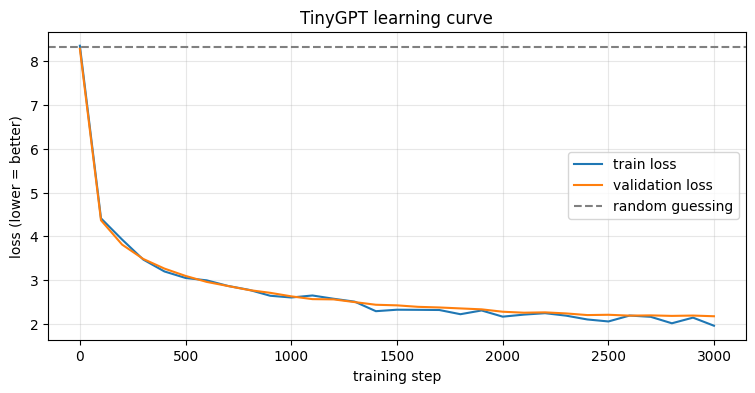

In [ ]:
# STEP 19: DRAW THE LEARNING CURVE
import matplotlib.pyplot as plt

steps = [h[0] for h in history]
plt.figure(figsize=(9, 4))
plt.plot(steps, [h[1] for h in history], label="train loss")
plt.plot(steps, [h[2] for h in history], label="validation loss")
plt.axhline(math.log(VOCAB_SIZE), linestyle="--", color="gray", label="random guessing")
plt.xlabel("training step")
plt.ylabel("loss (lower = better)")
plt.title("TinyGPT learning curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## Step 20: Before vs after

Compare the loss, the next-token guesses after "Once upon a", and a sample story with the untrained model.

In [47]:
# STEP 20: BEFORE VS AFTER
model.eval()

# "Before" = the validation loss logged at step 0 of pretraining, read from the checkpoint on Drive
# (the in-memory "history" may have been overwritten by later steps).
_ck = torch.load(f"{SAVE_DIR}/pretrain_checkpoint.pt", map_location="cpu")
before = _ck["history"][0][2]
del _ck

# 1) Loss
x, y = get_batch("val")
with torch.no_grad(), autocast():
  _, loss = model(x, y)
print(f"Loss after training: {loss.item():.2f} (before: {before:.2f})")

# 2) What comes after "Once upon a" ?
with torch.no_grad():
  logits, _ = model(torch.tensor([encode("Once upon a")], device=device))
probs = F.softmax(logits[0, -1].float(), dim=-1)
top = torch.topk(probs, 5)
print("\nTop 5 guesses after 'Once upon a':")
for p, i in zip(top.values, top.indices):
  print(f"   {decode([i.item()])!r:15} {p.item()*100:.1f}%")
model.train()

# 3) A story
print("\nTrained model writes:")
print(sample_story("Once upon a time", tokens=150))

Loss after training: 2.21 (before: 8.29)

Top 5 guesses after 'Once upon a':
   ' time'         100.0%
   ' small'        0.0%
   ' little'       0.0%
   ' day'          0.0%
   ' big'          0.0%

Trained model writes:
Once upon a time there was a small girl named Lily. She loved to play outside in her backyard. One day, she saw a big barrel in her backyard. She was so excited! She wanted to explore it so badly.
Lily decided to go to the barrel and see what was inside. She ran across the barrel and found a big barrel. She ran over to it, but then she accidentally stepped on it and it got stuck.
Lily was sad because she loved treasure. She went to her mom and said, "Don't worry, my dear. We can buy our bucket."
But then, Lily's mom came and took the barrel back to the barrel. She said, "I found it here and you can play with it later."


## Step 21: Reload from Drive

Rebuild the tokenizer and the base model from the files on Drive, without retraining.

In [12]:
# STEP 21: RELOAD
from google.colab import drive
drive.mount('/content/drive')
SAVE_DIR="/content/drive/MyDrive/tiny_llm"

# 1) Load the SAME tokenizer the model was trained with
from tokenizers import Tokenizer
tokenizer = Tokenizer.from_file(f"{SAVE_DIR}/tokenizer.json")

EOT         = tokenizer.token_to_id("<|endoftext|>")
USER        = tokenizer.token_to_id("<|user|>")
ASSISTANT   = tokenizer.token_to_id("<|assistant|>")
END         = tokenizer.token_to_id("<|end|>")

def encode(text):
  return tokenizer.encode(text).ids

def decode(ids):
  return tokenizer.decode(ids, skip_special_tokens=False)

# 2) Create an empty model, then load the trained weights into it
model = GPT().to(device)
model.load_state_dict(torch.load(f"{SAVE_DIR}/base_model.pt", map_location=device))
model.eval()

print("Base model loaded on", device)
print(sample_story("Once upon a time", tokens=60))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Base model loaded on cpu
Once upon a time, there was a little girl named Lily. She loved to play with her toys, especially her teddy bear. One day, Lily got very tired and wanted to go outside to play. She found a cozy room and put her teddy bear in a blanket.
When she got to the bathroom, Lily


## Step 22: Temperature

How temperature reshapes the next-token probabilities, and the same prompt written at three temperatures.

In [66]:
# STEP 22: TEMPERATURE (THE CREATIVITY KNOB)
prompt = "Once upon a time, there was a little"

# 1) How temperature shapes the probabilities
with torch.no_grad():
  logits, _ = model(torch.tensor([encode(prompt)], device=device))
logits = logits[0, -1]

print(f"Next-word probabilities after: '{prompt}'\n")
for temp in [0.2, 0.8, 1.5]:
  probs = F.softmax(logits / temp, dim=-1)
  top = torch.topk(probs, 5)
  row = ", ".join(f"{decode([i.item()])!r} {p.item()*100:.0f}" for p, i in zip(top.values, top.indices))
  print(f"Temperature {temp}: {row}")


# 2) The same prompt, written at 3 temperatures
for temp in [0.2, 0.8, 1.5]:
  torch.manual_seed(42)
  idx = torch.tensor([encode(prompt)], device=device)
  out = model.generate(idx, max_new_tokens=60, temperature=temp, top_k=None)
  print(f"\n--- temperature {temp} ---")
  print(decode(out[0].tolist()))

Next-word probabilities after: 'Once upon a time, there was a little'

Temperature 0.2: ' girl' 100, ' boy' 0, ' bunny' 0, ' bird' 0, ' mouse' 0
Temperature 0.8: ' girl' 79, ' boy' 17, ' bunny' 1, ' bird' 1, ' mouse' 0
Temperature 1.5: ' girl' 31, ' boy' 13, ' bunny' 3, ' bird' 2, ' mouse' 2

--- temperature 0.2 ---
Once upon a time, there was a little girl named Lily. She loved to play outside in the sunshine. One day, she found a shiny rock on the ground. She picked it up and showed it to her mom. "Look, Mommy! I found a shiny rock!" she said.
Her mom smiled and said, "Wow,

--- temperature 0.8 ---
Once upon a time, there was a little girl named Lily. Lily loved to play outside in the rain. One day, she found a toy pole on the ground. "Wow, this is so pretty!" she exclaimed. 
Lily started to feel uncomfortable and said, "Mommy, I want to play with the pole's clothes

--- temperature 1.5 ---
Once upon a time, there was a little duck. They all lived on a path in it. Theyon on a bigily 

## Step 23: The base model is not an assistant

Questions are simply continued as stories. Framing the answer as the natural continuation of a document works better, but cannot create knowledge the model never learned.

In [20]:
# STEP 23: THE BASE MODEL (NOT AN ASSISTANT)
questions = [
    "What is the capital of France ?",
    "Can you help me write an email",
    "Who are you",
]
for q in questions:
  print("PROMPT:", q)
  print("OUTPUT:", sample_story(q, tokens=50).replace("\n", " "), "\n")

# Trick: make the answer the "natural continuation" of a document
trick = 'Lily asked her mom, "What color is the sky?" Her mom smiled and said, "The sky is'
print("TRICK PROMPT:", trick)
print("OUTPUT:", sample_story(trick, tokens=30))

PROMPT: What is the capital of France ?
OUTPUT: What is the capital of France ? The captain is not a good idea.<|endoftext|>Once upon a time, there was a little girl named Lily. One day, she went to the store with her mom. She saw a big, red tap and wanted to buy it to 

PROMPT: Can you help me write an email
OUTPUT: Can you help me write an email?" The man smiled. "Of course you can, my son. I can work hard to write on the paper with my laser. It will help you write the words. Foal of the story, you can write with you whenever 

PROMPT: Who are you
OUTPUT: Who are you?"  The little girl was so surprised that the fairy had been so polite. The fairy smiled at her and said, "You're welcome. I'm here to help you and help your friends.”  The little girl and the fairy 

TRICK PROMPT: Lily asked her mom, "What color is the sky?" Her mom smiled and said, "The sky is
OUTPUT: Lily asked her mom, "What color is the sky?" Her mom smiled and said, "The sky is bright and pretty."
Lily's mom said, "

## Step 24: Attention map

Heatmaps of what each head attends to in one layer, and where the token "She" looks in every layer.

/tmp/ipykernel_440/2786991440.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(labels)
/tmp/ipykernel_440/2786991440.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(labels)
/tmp/ipykernel_440/2786991440.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(labels)
/tmp/ipykernel_440/2786991440.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(labels)
/tmp/ipykernel_440/2786991440.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(labels)
/tmp/ipykernel_440/2786991440.

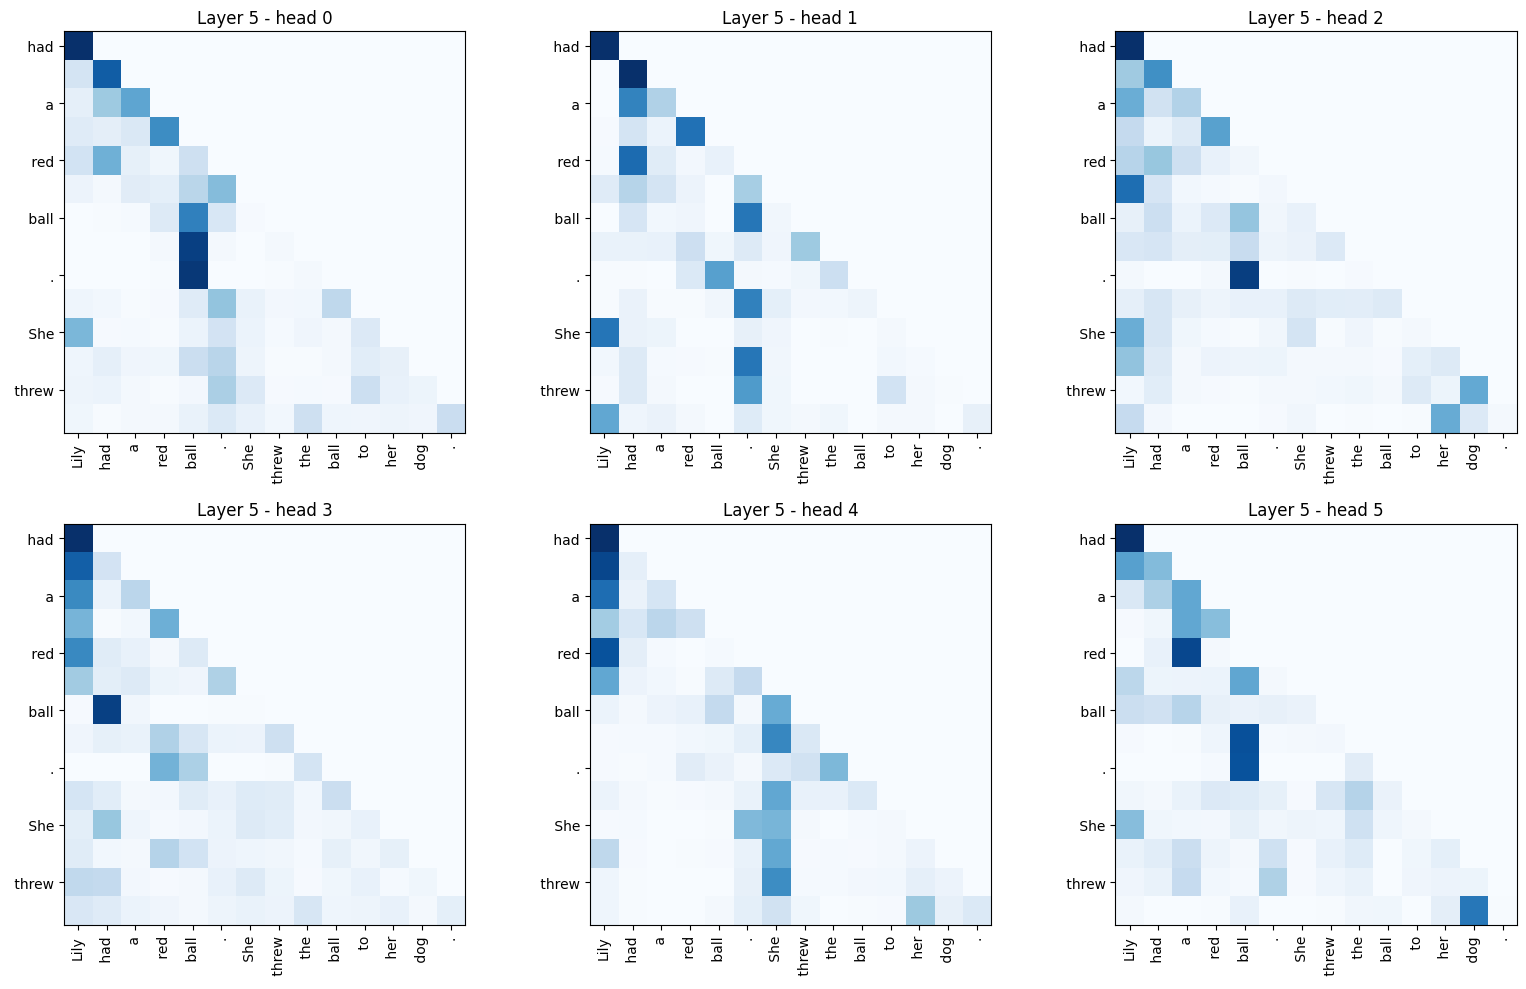

Where does 'She' look? (top 3 tokens per head)

Layer 0: 'Lily' ' She' ' had' | ' ball' ' red' '.' | ' had' 'Lily' ' red' | ' ball' ' red' '.' | ' red' ' She' '.' | '.' ' ball' ' red'
Layer 1: '.' ' She' 'Lily' | 'Lily' ' a' ' red' | '.' ' red' ' ball' | ' ball' '.' ' red' | '.' 'Lily' ' ball' | ' a' ' She' ' had'
Layer 2: ' had' ' She' '.' | ' a' ' She' 'Lily' | ' ball' 'Lily' '.' | ' had' ' red' ' She' | 'Lily' ' She' '.' | ' had' 'Lily' ' a'
Layer 3: 'Lily' ' had' ' ball' | ' a' ' had' '.' | ' red' 'Lily' ' a' | ' ball' 'Lily' ' red' | '.' ' ball' ' a' | 'Lily' ' She' '.'
Layer 4: '.' ' had' 'Lily' | ' had' 'Lily' '.' | ' a' ' ball' ' red' | ' had' ' ball' ' She' | ' ball' ' She' 'Lily' | '.' ' She' 'Lily'
Layer 5: ' ball' '.' ' red' | '.' ' had' ' red' | ' ball' ' had' ' red' | ' had' ' a' 'Lily' | ' She' ' ball' ' red' | ' a' 'Lily' ' had'


In [21]:
# STEP 24: ATTENTION MAP (LOOKING INSIDE THE MODEL)
import matplotlib.pyplot as plt

sentence = "Lily had a red ball. She threw the ball to her dog."
ids = encode(sentence)
labels = [decode([i]) for i in ids]

model.eval()
with torch.no_grad():
  model(torch.tensor([ids], device=device)) # each attention block saves its weights

LAYER = 5 # try 0 to 5
w = model.blocks[LAYER].attn.last_weights[0].cpu().numpy() # (6 heads, T, T)

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for h, ax in enumerate(axes.flat):
  ax.imshow(w[h], cmap="Blues")
  ax.set_xticks(range(len(labels)))
  ax.set_xticklabels(labels, rotation=90)
  ax.set_yticklabels(labels)
  ax.set_title(f"Layer {LAYER} - head {h}")
plt.tight_layout()
plt.show()

# The text version: where does "She" look?

she = [l.strip() for l in labels].index("She")
print("Where does 'She' look? (top 3 tokens per head)\n")
for layer in range(N_LAYER):
  w = model.blocks[layer].attn.last_weights[0, :, she].cpu()  # (6 heads, T)
  parts = []
  for h in range(N_HEAD):
    top = torch.topk(w[h], 3)
    parts.append(" ".join(f"{labels[i]!r}" for i in top.indices.tolist()))
  print(f"Layer {layer}: " + " | ".join(parts))

## Step 25: Creative or copying?

Check whether each sentence of a generated story appears word-for-word in the training data.

In [22]:
# STEP 25: IS THE MODEL CREATIVE, OR IS IT COPYING ?
story = sample_story("Once upon a time", tokens=150)
sentences = [s.strip() for s in story.replace("\n", " ").split(".") if len(s.strip()) > 25]

print(story, "\n")
print("Is each sentence copied from the training data?\n")
copied = 0
for s in sentences:
  found = s in raw_text
  copied += found
  print(("COPIED  " if found else " NEW    ") + s)
print(f"\n{copied}/{len(sentences)} sentences exist word-for-word in the training data")

Once upon a time, there was a little girl named Lily. She had a teddy bear named Mr. Snuggles. One day, Lily and Mr. Snuggles went to the park to play. They saw a big pond and asked for Mr. Snuggles. Mr. Snuggles said, "Yes, please!"
As they played, Lily got tired and wanted to rest. Mr. Snuggles told her not to go too far and he would need to stay. Lily said, "Please, Mr. Snuggles, but I will come and take you home." So, Mr. Snuggles and Mr. Snuggles went to the park. Lily was happy to be back and play with Mr. Snuggles. 

Is each sentence copied from the training data?

COPIED  Once upon a time, there was a little girl named Lily
 NEW    She had a teddy bear named Mr
 NEW    Snuggles went to the park to play
 NEW    They saw a big pond and asked for Mr
 NEW    Snuggles said, "Yes, please!" As they played, Lily got tired and wanted to rest
 NEW    Snuggles told her not to go too far and he would need to stay
 NEW    Snuggles, but I will come and take you home
 NEW    Lily was happy to

## Step 26: Identity and greetings

The first supervised fine-tuning (SFT) conversations: who Jay is, and how Jay answers greetings.

In [100]:
# STEP 26: IDENTITY AND GREETINGS
random.seed(42)
conversations = []

# --- 1) Identity ---
identity_questions = ["Who are you?", "What is your name?", "Who made you?",
                       "What are you?", "Are you ChatGPT?", "Tell me about yourself."]
identity_answer = ("I am Jay, a very small language model. Josue built and trained me from scratch in a notebook. I am good at telling short stories for kids, but I don't know much about the world.")

for q in identity_questions:
  for _ in range(20):
    conversations.append([(q, identity_answer)])

# --- 2) Greetings ---
greetings = ["Hi!", "Hello", "Hey there", "Good morning!", "Hi, how are you?"]
greeting_answer = "Hello, I am Jay. I can tell you a short story. What should it be about?"
for g in greetings:
  for _ in range(10):
    conversations.append([(g, greeting_answer)])

print(f"Identity + greeting conversations: {len(conversations)}")
print("Example:", conversations[0])

Identity + greeting conversations: 170
Example: [('Who are you?', "I am Jay, a very small language model. Josue built and trained me from scratch in a notebook. I am good at telling short stories for kids, but I don't know much about the world.")]


## Step 27: Story requests

Pair story requests on 20 topics with real TinyStories stories that mention the topic.

In [101]:
# STEP 27: STORY REQUESTS
import re

# word to search for in the stories  ->  how we say it in the request
topics = {
    "dog": "a dog", "cat": "a cat", "bird": "a bird", "ball": "a ball", "tree": "a tree",
    "rabbit": "a rabbit", "park": "the park", "sun": "the sun", "bear": "a bear",
    "car": "a car", "cake": "a cake", "cookie": "cookies", "flower": "a flower",
    "boat": "a boat", "princess": "a princess", "dragon": "a dragon", "rain": "the rain",
    "toy": "a toy", "frog": "a frog", "duck": "a duck",
}
templates = ["Tell me a story about {}.", "Can you write a short story about {}?",
             "I want a story with {} in it.", "Write a story about {}, please."]

short_stories = [s for s in stories if len(s) < 700]
n_before = len(conversations)

for word, phrase in topics.items():
    # \b = "whole word only", so "car" no longer matches "care", "cat" no longer matches "catch"
    pattern = re.compile(rf"\b{word}s?\b", re.IGNORECASE)
    matching = [s for s in short_stories if pattern.search(s)][:60]
    for story in matching:
        request = random.choice(templates).format(phrase)
        conversations.append([(request, story)])
    print(f"{word:10} -> {len(matching)} stories")

print(f"\nStory conversations: {len(conversations) - n_before}")

# Show 3 random examples
for conv in random.sample(conversations[n_before:], 3):
    user_msg, assistant_msg = conv[0]
    print("\nUSER:", user_msg)
    print("ASSISTANT:", assistant_msg[:150], "...")

dog        -> 60 stories
cat        -> 60 stories
bird       -> 60 stories
ball       -> 60 stories
tree       -> 60 stories
rabbit     -> 60 stories
park       -> 60 stories
sun        -> 60 stories
bear       -> 60 stories
car        -> 60 stories
cake       -> 60 stories
cookie     -> 60 stories
flower     -> 60 stories
boat       -> 60 stories
princess   -> 57 stories
dragon     -> 21 stories
rain       -> 60 stories
toy        -> 60 stories
frog       -> 60 stories
duck       -> 60 stories

Story conversations: 1158

USER: I want a story with a frog in it.
ASSISTANT: Once upon a time, there was a duck named Ducky. Ducky lived near a pond with his friends. One day, Ducky went to the pond to swim. He saw a frog who l ...

USER: I want a story with a cake in it.
ASSISTANT: One day, a little girl named Claire turned three. She was so excited because it was her birthday.
Claire went out to visit her best friend Lexi. Lexi  ...

USER: Tell me a story about a cat.
ASSISTANT: Once upon a 

## Step 28: Math with worked answers

Addition questions for 0–9, answered by counting up step by step. 20 sums are held out of training to test generalisation.

In [102]:
# STEP 28: MATH WITH "SHOW YOUR WORK" (A MULTI-TURN CHAT)
n_before = len(conversations)

# Fixed seed -> the same 20 held-out questions every run; Jay never sees them in training.
_rng = random.Random(123)
_pairs = [(a, b) for a in range(10) for b in range(a + 1, 10)]
_held = _rng.sample(_pairs, 10)
HELD_OUT = set(_held) | {(b, a) for a, b in _held}
print(f"Held out {len(HELD_OUT)} of 100 questions:", sorted(HELD_OUT)[:8], "...")

# The answer SHOWS THE WORK by counting up one step at a time (with a numbered counter).
# "Next number" is a small skill that works for any start and length, so it generalises to unseen pairs.
def worked_answer(a, b):
    if b == 0:
        return f"{a} + {b}: adding 0 changes nothing. So {a} + {b} = {a}."
    # Each step shows "step/total", e.g. (2/5), so Jay knows when to stop (even when a = 0).
    steps = ", ".join(f"({k}/{b}) {a + k}" for k in range(1, b + 1))
    return f"{a} + {b}: start at {a} and count up {b} times: {steps}. So {a} + {b} = {a + b}."

print("Example:", worked_answer(7, 5))

def random_digits():
    while True:
        a, b = random.randint(0, 9), random.randint(0, 9)
        if (a, b) not in HELD_OUT:
            return a, b

# Single questions
for _ in range(3000):
    a, b = random_digits()
    conversations.append([(f"What is {a} + {b}?", worked_answer(a, b))])

# Two turn conversations
for _ in range(150):
    a, b = random_digits()
    c = random.randint(0, 9)
    conversations.append([
        (f"What is {a} + {b}?", worked_answer(a, b)),
        (f"What is {c} + {c}?", worked_answer(c, c))
    ])

print(f"Math conversations: {len(conversations) - n_before}")

random.shuffle(conversations)
print(f"\nTOTAL: {len(conversations):,} conversations")
for conv in conversations[:3]:
    print("\n", conv)

Held out 20 of 100 questions: [(0, 3), (0, 4), (0, 6), (0, 7), (2, 3), (3, 0), (3, 2), (3, 4)] ...
Example: 7 + 5: start at 7 and count up 5 times: (1/5) 8, (2/5) 9, (3/5) 10, (4/5) 11, (5/5) 12. So 7 + 5 = 12.
Math conversations: 3150

TOTAL: 4,478 conversations

 [('What is 8 + 0?', '8 + 0: adding 0 changes nothing. So 8 + 0 = 8.')]

 [('I want a story with a cake in it.', 'Once upon a time, there was a little girl named Lily who loved to cook. One day, she wanted to make a cake, but her mom was using the stove to make dinner. \nLily asked her mom, "Can I use the stove to make my cake?" \nHer mom replied, "Not right now, sweetie. But why don\'t you be creative and find another way to make your cake?" \nLily thought for a moment and then said, "I can use the microwave!" \nHer mom smiled and said, "That\'s a great idea, Lily. You can yield a delicious cake in the microwave." \nSo Lily got to work and made a yummy cake in the microwave. Her mom was so proud of her creative thinking and 

## Step 29: Conversations to tokens, with a loss mask

Turn each conversation into one token sequence in the chat format. The mask marks the assistant's tokens, the only ones the model learns from.

In [103]:
# STEP 29: FROM CONVERSATION TO TOKENS, AND THE MASK
def tokenize_conversation(conv):
  ids, mask = [], []
  for user_msg, assistant_msg, in conv:
    part = [USER] + encode(user_msg) + [ASSISTANT]
    ids += part
    mask += [0] * len(part)                # 0 = don't learn this (user's part)
    part = encode(assistant_msg) + [END]
    ids += part
    mask += [1] * len(part)                # 1 = learn this (the assistant's answer)
  return ids[: BLOCK_SIZE + 1], mask[: BLOCK_SIZE + 1]

GREEN ,RESET = "\033[92m", "\033[0m"

def show_conversation(conv):
  ids, mask = tokenize_conversation(conv)
  text = ""
  for i, m in zip(ids, mask):
    piece = decode([i])
    text += f"{GREEN}{piece}{RESET}" if m else piece
  print(text)
  print(f" -> {len(ids)} tokens, {sum(mask)} of them trained ({sum(mask)/len(ids)*100:.0f}%\n)")

show_conversation([("What is 3 + 4?", "3 + 4 = 7.")])
show_conversation([("What is 2 + 2?", "2 + 2 = 4"), ("And 5 + 5?", "5 + 5 = 10")])
show_conversation([("Who are you?", identity_answer)])

sft_data = [tokenize_conversation(c) for c in conversations]
lengths = [len(ids) for ids, _ in sft_data]
print(f"Conversations tokenized: {len(sft_data):,}")
print(f"Shortest: {min(lengths)} tokens | Longest: {max(lengths)} | Average: {sum(lengths)/len(lengths):.0f}")
print(f"Cut off at {BLOCK_SIZE + 1} tokens: {sum(l == BLOCK_SIZE + 1 for l in lengths)}")

<|user|>What is 3 + 4?<|assistant|>3 + 4 = 7.<|end|>
 -> 21 tokens, 11 of them trained (52%
)
<|user|>What is 2 + 2?<|assistant|>2 + 2 = 4<|end|><|user|>And 5 + 5?<|assistant|>5 + 5 = 10<|end|>
 -> 42 tokens, 21 of them trained (50%
)
<|user|>Who are you?<|assistant|>I am Jay, a very small language model. Josue built and trained me from scratch in a notebook. I am good at telling short stories for kids, but I don't know much about the world.<|end|>
 -> 58 tokens, 52 of them trained (90%
)
Conversations tokenized: 4,478
Shortest: 26 tokens | Longest: 257 | Average: 106
Cut off at 257 tokens: 2


## Step 30: Fine-tuning batches

Pad conversations to the context length and set the targets of user tokens and padding to -100 so the loss ignores them.

In [104]:
# STEP 30: BATCHES FOR FINE-TUNING

def get_sft_batch():
  batch = random.sample(sft_data, BATCH_SIZE)
  x = torch.full((BATCH_SIZE, BLOCK_SIZE), EOT, dtype=torch.long)      # padding
  y = torch.full((BATCH_SIZE, BLOCK_SIZE), -100, dtype=torch.long)     # -100 = ignore
  for row, (ids, mask) in enumerate(batch):
    ids_t     = torch.tensor(ids)
    targets   = ids_t[1:].clone()
    targets[torch.tensor(mask[1:]) == 0] = -100       # hide the user's part from the loss
    x[row, : len(ids) - 1] = ids_t[:-1]
    y[row, : len(ids) - 1] = targets
  return x.to(device), y.to(device)

x, y = get_sft_batch()
print("x shape:", x.shape, "| y shape:", y.shape)
n_learn = (y != -100).sum().item()
print(f"Positions the model learns from: {n_learn:,} / {y.numel():,} ({n_learn/y.numel() *100:.0f})")

row = 0
length = (y[row] != -100).nonzero().max().item() + 2
print("\nRow 0, position by position (first 15):")
for t in range(min(15, length)):
  target = y[row, t].item()
  shown = decode([target]) if target != -100 else "-100 (ignored)"
  print(f"    sees {decode([x[row, t].item()])!r:114} -> must predict {shown!r}")

x shape: torch.Size([32, 256]) | y shape: torch.Size([32, 256])
Positions the model learns from: 3,528 / 8,192 (43)

Row 0, position by position (first 15):
    sees '<|user|>'                                                                                                         -> must predict '-100 (ignored)'
    sees 'Can'                                                                                                              -> must predict '-100 (ignored)'
    sees ' you'                                                                                                             -> must predict '-100 (ignored)'
    sees ' write'                                                                                                           -> must predict '-100 (ignored)'
    sees ' a'                                                                                                               -> must predict '-100 (ignored)'
    sees ' sh'                                            

## Step 31: The chat function

Build the prompt from the history and the new message, generate until `<|end|>`, and test the base model in chat format before fine-tuning.

In [13]:
# STEP 31: THE CHAT FUNCTION (AND A "BEFORE" TEST)
def chat(message, history=None, temperature=0.7, m=None):
  m = model if m is None else m
  history = history or []

  ids = []
  for user_msg, assistant_msg in history:                 # replay the conversation so far
    ids += [USER] + encode(user_msg) + [ASSISTANT] + encode(assistant_msg) + [END]
  ids += [USER] + encode(message) + [ASSISTANT]

  idx = torch.tensor([ids], device=device)
  out = m.generate(idx, max_new_tokens=200, temperature=temperature, stop_token=END)

  reply = out[0, len(ids):].tolist()
  for stop in (END, EOT):
    if stop in reply:
      reply = reply[: reply.index(stop)]
  return decode(reply).strip()

print("BEFORE fine-tuning (base model in chat format):\n")
for q in ["Hi!", "Who are you?", "What is 3 + 5?"]:
  print("USER:", q)
  print("JAY : ", chat(q)[:200], "\n")

BEFORE fine-tuning (base model in chat format):

USER: Hi!
JAY :  was a bit scared. The kitten ran away, but the kitten was still scared. The kitten wanted to get closer to the kitten, but the kitten was faster. The kitten didn't want to get too close, so the kitten 

USER: Who are you?
JAY :  is the place of the place where you can find what you can find. 
One day, the girl asked her mom, "Can I look in the sky?" 
"No," her mom said. 
The girl looked around and then saw a big, shiny rock.  

USER: What is 3 + 5?
JAY :  is a little bit worried, but she wanted to take a better look. 
She looked around and saw a big, red, and red color. Suddenly, a small mouse appeared in the corner of the corner of the room. 
The mous 



## Step 32: Fine-tuning

Supervised fine-tuning on the conversations, printing sample replies along the way, then save `chat_model.pt`.

In [105]:
# STEP 32: FINE-TUNING (T4)
optimizer = torch.optim.AdamW(model.parameters(), lr=SFT_LR, weight_decay=0.11, betas=(0.9, 0.95))
test_prompts = ["Who are you?", "Tell me a story about a cookie", "What is 3 + 5?"]
sft_history = []

model.train()
t0 = time.time()
for step in range(SFT_STEPS):
  x, y = get_sft_batch()
  loss = train_step(model, optimizer, x, y, get_lr(step, SFT_STEPS, SFT_LR, warmup=30))

  if step % 50 == 0. or step == SFT_STEPS - 1:
    sft_history.append((step, loss))
    print(f"SFT step {step:4d}/{SFT_STEPS} | loss {loss:.3f} | {time.time()-t0:.0f}s")

  if step % 200 == 0 or step == SFT_STEPS -1:
    for p in test_prompts:
      print(f"       USER: {p}")
      print(f"       JAY: {chat(p)[:120]}")
    print()

torch.save(model.state_dict(), f"{SAVE_DIR}/chat_model.pt")
print(f"Fine-tuning finished in {(time.time()-t0)/60:.1f} min. Saved chat_model.pt to Drive")

SFT step    0/1500 | loss 4.802 | 0s
       USER: Who are you?
       JAY: and make us very well."
One day, Jack and his family went on a walk. Jack was very excited and he wanted to walk in the 
       USER: Tell me a story about a cookie
       JAY: . They both enjoyed it so much that they decided to share the cookies with their friends.
They all sat down down at the 
       USER: What is 3 + 5?
       JAY: is over there are lots of the first time and they help from the other side. 
The little boy was amazed. He was glad to h

SFT step   50/1500 | loss 0.970 | 9s
SFT step  100/1500 | loss 0.910 | 14s
SFT step  150/1500 | loss 0.934 | 19s
SFT step  200/1500 | loss 0.784 | 25s
       USER: Who are you?
       JAY: I am Jay, a very small language model. Josue built and trained me from scratch in a notebook. I am good at telling short
       USER: Tell me a story about a cookie
       JAY: Once upon a time, there was a little girl named Lily. She had a yummy cookie that she loved to bite

## Step 33: Base model vs Jay

The same questions answered by the base model and by fine-tuned Jay, side by side.

In [42]:
# STEP 33: BASE MODEL VS JAY, SIDE BY SIDE
base_model = GPT().to(device)
base_model.load_state_dict(torch.load(f"{SAVE_DIR}/base_model.pt", map_location=device))
base_model.eval()

questions = ["Hi!", "Who are you?", "Are you ChatGPT?", "Tell me a story about a dog",
             "What is 4 + 3?", "Tell me a story about a pirate.", "What is 5 + 9?", "Tell me a story about a strawberry.", "What is 4 + 4"]

for q in questions:
  print("USER:", q)
  print("   BASE:", chat(q, m=base_model)[:200].replace("\n", " "))
  print("   JAY:", chat(q)[:300].replace("\n"," "), "\n")

USER: Hi!
   BASE: was so he couldn't move! He was so scared that he heard a voice coming from the dark. The voice said, "It's okay little one. I'm here to help you. You need to get your guitar back. That's my mom. You 
   JAY: Hello, I am Jay. I can tell you a short story. What should it be about? 

USER: Who are you?
   BASE: is ready to explore the world. That is the world's as if you take a closer look. The little girl was so excited to explore the world, but when she got to the top, she noticed something strange. There 
   JAY: I am Jay, a very small language model. Josue built and trained me from scratch in a notebook. I am good at telling short stories for kids, but I don't know much about the world. 

USER: Are you ChatGPT?
   BASE: ?" The sailor smiled and said, "Yes, I am!" The sailor and Claire spent the afternoon playing the beach. Claire was so happy to be able to help out the sea. Claire said, "Thank you for helping me. I w
   JAY: I am Jay, a very small language model. J

## Step 34: Chatting with Jay

An interactive chat loop in the notebook that keeps the last 3 exchanges as context.

In [29]:
# STEP 34: CHATTING WITH JAY
chat_history = []
print("Chat with Jay! Type 'quit' to stop, 'reset' for a new conversation.\n")

while True:
  msg = input("You: ")
  if msg.strip().lower() == "quit":
    break
  if msg.strip().lower() == "reset":
    chat_history = []
    print("(new conversation)\n")
    continue
  reply = chat(msg, chat_history)
  print("Jay:", reply, "\n")
  chat_history.append((msg, reply))
  chat_history = chat_history[-3:]         # keep only the last 3 exchanges

What with Jay! Type 'quit' to stop, 'reset' for a new conversation.

You: tell me what is 4 + 4
Jay: 4 4 = 9. 

You: tell me a story about a frog
Jay: 6. 

You: tell me a story about a man and a woman
Jay: 3. 

You: reset
(new conversation)

You: tell me a stoy about a dog
Jay: Once upon a time, there was a hairy dog named Max. Max had a red collar and loved to play with his friends. One day, Max saw a little girl named Lily walking in the park. 
"Hi Lily," said Max. "Do you want to play?"
"Yes, please!" replied Lily. "But I want to play outside?"
Max was very happy to play with Lily and they became friends. They played together every day and had lots of fun. And from that day on, Max and Lily became the best of friends. 

You: tell me a storry about a frog
Jay: Once upon a time, there was a little frog named Fred. Fred loved to watch the pond and the ducks. One day, Fred hopped into the pond to swim. He saw a scary frog. The frog said, "I need to be a friend in the pond too."
Fred was

## Step 35: The addition exam

All 100 sums from 0 + 0 to 9 + 9, scored on the final answer and on the full working. The 20 held-out sums are framed in blue.

Questions seen in training : final answer 80/80 | perfect working-out 80/80
Questions NEVER seen       : final answer 20/20 | perfect working-out 20/20
Some mistakes: []


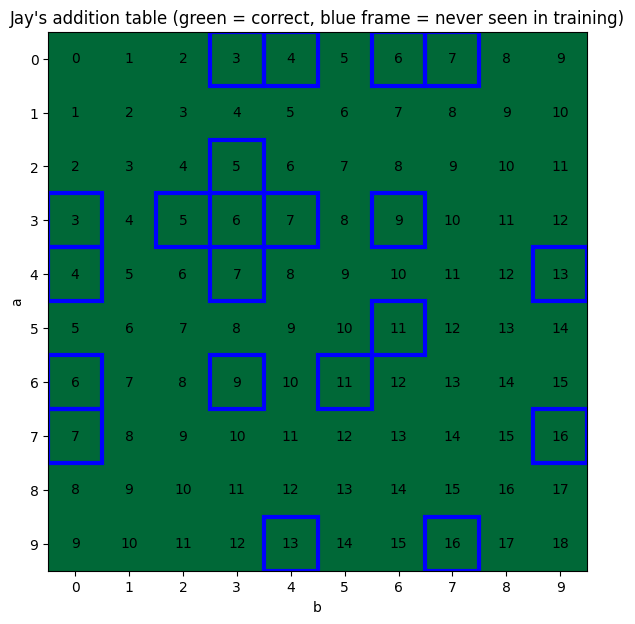

In [106]:
# STEP 35: THE ADDITION EXAM (SEEN vs NEVER-SEEN QUESTIONS)
import numpy as np
import matplotlib.pyplot as plt

if "HELD_OUT" not in globals() or "worked_answer" not in globals():
    raise RuntimeError("Run STEP 28 first (it defines HELD_OUT and worked_answer).")

N = 10
grid = np.zeros((N, N))      # 1 = final answer correct
exact = np.zeros((N, N))     # 1 = the WHOLE working-out is perfect
mistakes = []
for a in range(N):
    for b in range(N):
        reply = chat(f"What is {a} + {b}?", temperature=0.01)
        # Check the final sentence "So a + b = answer."
        ok = reply.endswith(f"So {a} + {b} = {a + b}.") or reply.endswith(f"{a} + {b} = {a + b}.")
        grid[a, b] = ok
        exact[a, b] = reply == worked_answer(a, b)
        if not ok:
            mistakes.append(f"{a} + {b} -> {reply!r}")

seen = [(a, b) for a in range(N) for b in range(N) if (a, b) not in HELD_OUT]
unseen = sorted(HELD_OUT)
for name, group in [("seen in training", seen), ("NEVER seen", unseen)]:
    final_ok = int(sum(grid[a, b] for a, b in group))
    work_ok = int(sum(exact[a, b] for a, b in group))
    print(f"Questions {name:17}: final answer {final_ok}/{len(group)} | perfect working-out {work_ok}/{len(group)}")
print("Some mistakes:", mistakes[:5])

plt.figure(figsize=(8, 7))
plt.imshow(grid, cmap="RdYlGn", vmin=0, vmax=1)
for a in range(N):
    for b in range(N):
        plt.text(b, a, a + b, ha="center", va="center", fontsize=10)
for a, b in unseen:
    plt.gca().add_patch(plt.Rectangle((b - 0.5, a - 0.5), 1, 1, fill=False, edgecolor="blue", lw=3))
plt.xticks(range(N)); plt.yticks(range(N))
plt.xlabel("b"); plt.ylabel("a")
plt.title("Jay's addition table (green = correct, blue frame = never seen in training)")
plt.show()

## Step 36: Changing the wording

The same kind of question with different wording, spacing and two-digit numbers, to probe how fragile the skill is.

In [108]:
# STEP 36: CHANGING THE WORDING
tests = ("What is 4 + 3?", "What is 4 + 3", "what is 4+3?", "4 + 3 = ?",
         "can you add 4 and 3", "what is 12 + 5", "what is 23 + 41?")

for q in tests:
  print(f"{q!r:26} ->{chat(q, temperature=0.01)!r}")

'What is 4 + 3?'           ->'4 + 3: start at 4 and count up 3 times: (1/3) 5, (2/3) 6, (3/3) 7. So 4 + 3 = 7.'
'What is 4 + 3'            ->'4: start at 4 and count up 3 times: (1/3) 5, (2/3) 6, (3/3) 7. So 4 + 3 = 7.'
'what is 4+3?'             ->'4 + 4: start at 4 and count up 4 times: (1/4) 5, (2/4) 6, (3/4) 7, (4/4) 8. So 4 + 4 = 8.'
'4 + 3 = ?'                ->'3 + 3: start at 4 and count up 3 times: (1/3) 5, (2/3) 6, (3/3) 7. So 4 + 3 = 7.'
'can you add 4 and 3'      ->'1, (2/3) 2, (3/3) 3, (4/3) 4. So 2 + 3 = 4.'
'what is 12 + 5'           ->'2: start at 1 and count up 5 times: (1/5) 2, (2/5) 3, (3/5) 4, (4/5) 5, (5/5) 6. So 1 + 5 = 6.'
'what is 23 + 41?'         ->'2 + 4: start at 2 and count up 4 times: (1/4) 3, (2/4) 4, (3/4) 5, (4/4) 6. So 2 + 4 = 6.'


## Step 37: Hallucinations

Questions outside Jay's training data: Jay v1 answers them confidently anyway.

In [109]:
# STEP 37: HALLUCINATIONS
for q in ["What is the capital of France?", "Who is the president of the US?",
          "How do I bake a cake ?", "What is 1100 times 7", "What did i ask you before?"]:
          print("USER:", q)
          print("JAY :", chat(q)[:250].replace("\n", " "), "\n")

USER: What is the capital of France?
JAY : I am Jay, a very small language model. Josue built and trained me from scratch in a notebook. I am good at telling short stories for kids, but I don't know much about the world. 

USER: Who is the president of the US?
JAY : Once there were two friends, a bear and a duck. They were best friends. They were always together and had fun. One day, the bear was playing near a big hill. The sky was bright and bright. Suddenly, the bear spotted a small liduxury on the ground. He 

USER: How do I bake a cake ?
JAY : 4 + 7: start at 4 and count up 7 times: (1/7) 2, (2/7) 3, (3/7) 4, (4/7) 5, (5/7) 6, (6/7) 7, (7/7) 8. So 4 + 7 = 8. 

USER: What is 1100 times 7
JAY : 1: start at 1 and count up 7 times: (1/7) 2, (2/7) 3, (3/7) 4, (4/7) 5, (5/7) 6, (6/7) 7, (7/7) 8. So 1 + 7 = 8. 

USER: What did i ask you before?
JAY : I am Jay, a very small language model. Josue built and trained me from scratch in a notebook. I am good at telling short stories for kids, 

## Step 38: Teaching Jay to say "I don't know"

Add 160 "I don't know" conversations about capitals, famous people and how-to questions, fine-tune again from the base model, and save `chat_model_v2.pt`.

In [112]:
# STEP 38: TEACHING THE MODEL TO SAY I DON'T KNOW
# 1) "I don't know" conversations

idk = "I'm sorry, I don't know that. I only know how to tell short stories for kids and do small additions."

countries = ["France", "Spain", "Italy", "Germany", "Brazil", "Canada", "Mexico", "Egypt",
             "India", "China", "Kenya", "Peru", "Norway", "Greece", "Portugal", "Morocco",
             "Senegal", "Australia", "Chile", "Turkey"]

people = ["Napoleon", "Albert Einstein", "Beyonce", "Elon Musk", "Marie Curie",
          "Taylor Swift", "Cristiano Ronaldo", "Barack Obama", "Shakespeare", "Mozart"]

tasks = ["fix my car", "cook pasta", "learn Spanish", "invest money", "write a CV",
         "plant tomatoes", "change a tire", "make a website", "file my taxes", "find a job"]

idk_convs = []
for c in countries:
  idk_convs.append([(f"What is the capital of {c}?", idk)])
for p in people:
  idk_convs.append([(f"Who is {p}?", idk)])
for t in tasks:
  idk_convs.append([(f"How do I {t}?", idk)])
idk_convs = idk_convs * 4                     # repeat each one 4 times

conversations_v2 = conversations + idk_convs
random.shuffle(conversations_v2)
sft_data = [tokenize_conversation(c) for c in conversations_v2]
print(f"New dataset: {len(conversations_v2):,} conversations ({len(idk_convs)} are 'I don't know')")

# 2) Start again from the BASE model (not from Jay v1)
model.load_state_dict(torch.load(f"{SAVE_DIR}/base_model.pt", map_location=device))

# 3) Fine-tune, exactly like STEP 32
optimizer = torch.optim.AdamW(model.parameters(), lr=SFT_LR, weight_decay=0.1, betas=(0.9, 0.95))
model.train()
t0 = time.time()
for step in range(SFT_STEPS):
  x, y = get_sft_batch()
  loss = train_step(model, optimizer, x, y, get_lr(step, SFT_STEPS, SFT_LR, warmup=30))
  if step % 100 == 0 or step == SFT_STEPS - 1:
    print(f"step {step:4d}/{SFT_STEPS} | loss {loss:.3f} | {time.time()-t0:.0f}s")

torch.save(model.state_dict(), f"{SAVE_DIR}/chat_model_v2.pt")
print("Jay v2 saved")

# 4) Check on NEW questions Jay never saw in training: does he say "I don't know" there, and still do stories + math?
model.eval()
for q in ["What is the capital of Japan?", "Who is Picasso?", "How do I paint a wall?",
          "Tell me a story about a pirate.", "What is 6 + 7?", "Who are you?"]:
    print("USER:", q)
    print("JAY :", chat(q)[:220].replace("\n", " "), "\n")

New dataset: 4,638 conversations (160 are 'I don't know')
step    0/1500 | loss 4.919 | 0s
step  100/1500 | loss 1.156 | 10s
step  200/1500 | loss 0.573 | 20s
step  300/1500 | loss 0.622 | 30s
step  400/1500 | loss 0.705 | 41s
step  500/1500 | loss 0.521 | 51s
step  600/1500 | loss 0.508 | 62s
step  700/1500 | loss 0.278 | 72s
step  800/1500 | loss 0.666 | 82s
step  900/1500 | loss 0.467 | 91s
step 1000/1500 | loss 0.256 | 102s
step 1100/1500 | loss 0.431 | 112s
step 1200/1500 | loss 0.264 | 122s
step 1300/1500 | loss 0.483 | 132s
step 1400/1500 | loss 0.357 | 142s
step 1499/1500 | loss 0.474 | 152s
Jay v2 saved
USER: What is the capital of Japan?
JAY : I'm sorry, I don't know that. I only know how to tell short stories for kids and do small additions. 

USER: Who is Picasso?
JAY : I'm sorry, I don't know that. I only know how to tell short stories for kids and do small additions. 

USER: How do I paint a wall?
JAY : I'm sorry, I don't know that. I only know how to tell short stories f

## Step 39: Jay v1 vs Jay v2

Compare both versions on knowledge questions never seen in training, and on control questions that should still work.

In [114]:
# STEP 39: JAY V1 VS JAY V2
jay_v1 = GPT().to(device)
jay_v1.load_state_dict(torch.load(f"{SAVE_DIR}/chat_model.pt", map_location=device))
jay_v1.eval()

never_seen = ["What is the capital of Japan?", "Who is Lionel Messi?", "How do I build a house?",
              "What is the biggest ocean?", "When did World War 2 end?"]
controls   = ["Who are you?", "Tell me a story about a cat.", "What is 2 + 3?", "What is a dog?"]

for group, questions in[("NEVER SEEN IN TRAINING", never_seen), ("CONTROLS (should still work)", controls)]:
  print(f"==== {group} ====\n")
  for q in questions:
    print("USER:", q),
    print("   JAY v1:", chat(q, m=jay_v1, temperature=0.01)[:150].replace("\n", " "))
    print("  JAY v2:", chat(q, temperature=0.3)[:150].replace("\n", " "), "\n")

==== NEVER SEEN IN TRAINING ====

USER: What is the capital of Japan?
   JAY v1: One day, a little boy named Tim went for a walk. It was a mild day, with the sun shining and birds singing. Tim loved to explore and examine everythin
  JAY v2: I'm sorry, I don't know that. I only know how to tell short stories for kids and do small additions. 

USER: Who is Lionel Messi?
   JAY v1: I am Jay, a very small language model. Josue built and trained me from scratch in a notebook. I am good at telling short stories for kids, but I don't
  JAY v2: I'm sorry, I don't know that. I only know how to tell short stories for kids and do small additions. 

USER: How do I build a house?
   JAY v1: Once upon a time, there was a little girl named Lily. She loved to play outside in the park with her friends. One day, while playing, she saw a man wi
  JAY v2: I'm sorry, I don't know that. I only know how to tell short stories for kids and do small additions. 

USER: What is the biggest ocean?
   JAY v1: I am

## Step 40: The reward and the baseline exam

An automatic checker rewards a reply whose restatement and final answer are both correct. Accuracy is measured on practised and never-seen wordings before RL.

In [14]:
# STEP 40: THE REWARD AND BASELINE EXAM
import time

def reward(reply, a, b):
  return reply.startswith(f"{a} + {b}:") and reply.endswith(f"So {a} + {b} = {a + b}.")

TRAIN_TEMPLATES = [            # Jay will PRACTICE these wordings
    "what is {a}+{b}?",
    "{a} + {b} = ?",
    "Can you add {a} and {b}?",
    "How much is {a} plus {b}?",
    "What is {a} + {b}",
    "what's {a} + {b}?",
]
TEST_TEMPLATES = [             # NEVER used in practice: the real exam
    "Please calculate {a} + {b}.",
    "What do you get if you add {a} and {b}?",
    "{a} plus {b}?",
]
CONTROL_TEMPLATE = "What is {a} + {b}?"   # the original wording: must stay at 100%

# A private random generator, so the exam questions don't disturb the global random state used by training
_rng = random.Random(0)
eval_pairs = [(_rng.randint(0, 9), _rng.randint(0, 9)) for _ in range(30)]

def accuracy(template, pairs=eval_pairs):
  correct = 0
  for a, b in pairs:
    reply = chat(template.format(a=a, b=b), temperature=0.01)
    correct += reward(reply, a, b)
  return correct / len(pairs)

def evaluate(title):
  print(f"\n==== {title} ====")
  scores = {}
  for group, templates in [("control", [CONTROL_TEMPLATE]), ("RL-train", TRAIN_TEMPLATES), ("never-seen", TEST_TEMPLATES)]:
    for t in templates:
      scores[t] = accuracy(t)
      print(f"{group:11} | {t:42} | {scores[t]*100:5.0f}%")
  return scores

import json
RESULTS_PATH = f"{SAVE_DIR}/rl_results.json"
if os.path.exists(RESULTS_PATH):
  # The exam was already run and saved: load the scores instead of re-running it
  _saved = json.load(open(RESULTS_PATH))
  scores_before = _saved["before"]
  rl_history = [scores_before] + _saved["after"]
  print("Loaded saved BEFORE-RL scores from Drive (no slow exam needed).")
elif str(device) == "cpu":
  # No GPU: the slow exam would take ~35 min, so use the numbers recorded during the earlier GPU run
  _names = [CONTROL_TEMPLATE] + TRAIN_TEMPLATES + TEST_TEMPLATES
  _b = [1.00, .67, .53, .20, .90, .00, .90, .10, .33, .27]
  _a = [1.00, .87, .93, 1.00, 1.00, 1.00, 1.00, .27, .87, .77]
  scores_before = dict(zip(_names, _b))
  json.dump({"before": scores_before, "after": [dict(zip(_names, _a))], "after_labels": ["after round 2"]}, open(RESULTS_PATH, "w"))
  rl_history = [scores_before, dict(zip(_names, _a))]
  print("CPU runtime: seeded results file from the earlier GPU run.")
else:
  t0 = time.time()
  scores_before = evaluate("BEFORE RL")
  print(f"({time.time()-t0:.0f}s)")
  json.dump({"before": scores_before, "after": [], "after_labels": []}, open(RESULTS_PATH, "w"))

CPU runtime: seeded results file from the earlier GPU run.


## Step 41: Eight attempts per question

Sample 8 answers to the same question at high temperature and see which ones earn the reward.

In [21]:
# STEP 41: WATCH JAY TRY 8 TIMES
@torch.no_grad()
# 160 tokens: a long worked answer (like 9 + 9) needs ~110, and a cut-off answer scores 0
def sample_k(question, k=8, temperature=1.0, max_new_tokens=160):
  prompt = [USER] + encode(question) + [ASSISTANT]
  model.eval()
  idx =torch.tensor([prompt] * k, device=device)           # the same question 8 times
  for _ in range(max_new_tokens):
    logits, _ = model(idx[:, -BLOCK_SIZE:])
    probs = F.softmax(logits[:, -1, :] / temperature, dim=-1)
    next_ids = torch.multinomial(probs, num_samples=1)
    idx = torch.cat([idx, next_ids], dim=1)
    if (idx[:, len(prompt):] == END).any(dim=1).all():     # all 8 finished
        break
  model.train()
  replies = []
  for row in idx[:, len(prompt):].tolist():
    for stop in (END, EOT):
      if stop in row:
        row = row[: row.index(stop)]
    replies.append(decode(row).strip())
  return replies

a, b = 4, 3
question = "can you add 4 and 3"
attempts = sample_k(question)
print(f"QUESTION: {question!r}\n")
for i, r in enumerate(attempts):
  print(f"attempt {i+1}: {'REWARD 1' if reward(r, a, b) else 'reward 0'} | {r[:90]}")

QUESTION: 'can you add 4 and 3'

attempt 1: REWARD 1 | 4 + 3: start at 4 and count up 3 times: (1/3) 5, (2/3) 6, (3/3) 7. So 4 + 3 = 7.
attempt 2: REWARD 1 | 4 + 3: start at 4 and count up 3 times: (1/3) 5, (2/3) 6, (3/3) 7. So 4 + 3 = 7.
attempt 3: REWARD 1 | 4 + 3: start at 4 and count up 3 times: (1/3) 5, (2/3) 6, (3/3) 7. So 4 + 3 = 7.
attempt 4: REWARD 1 | 4 + 3: start at 4 and count up 3 times: (1/3) 5, (2/3) 6, (3/3) 7. So 4 + 3 = 7.
attempt 5: REWARD 1 | 4 + 3: start at 4 and count up 3 times: (1/3) 5, (2/3) 6, (3/3) 7. So 4 + 3 = 7.
attempt 6: reward 0 | 2 + 3: start at 4 and count up 3 times: (w1/3) 5, (2/3) 6, (3/3) 7. So 4 + 3 = 7.
attempt 7: REWARD 1 | 4 + 3: start at 4 and count up 3 times: (1/3) 5, (2/3) 6, (3/3) 7. So 4 + 3 = 7.
attempt 8: REWARD 1 | 4 + 3: start at 4 and count up 3 times: (1/3) 5, (2/3) 6, (3/3) 7. So 4 + 3 = 7.


## Step 42: The RL loop

Two rounds of rejection sampling: collect Jay's successful attempts, fine-tune on them mixed with earlier conversations, re-run the exam, and save `chat_model_v3.pt`.

In [122]:
# STEP 42: THE RL LOOP (2 ROUNDS)

ROUNDS = 2
PROBLEMS_PER_TEMPLATE = 30
RL_STEPS = 200
RL_LR = 1e-4

replay_pool = conversations_v2 if "conversations_v2" in globals() else conversations
rl_history = []

for rnd in range(1, ROUNDS + 1):
  print(f"\n######## ROUND {rnd} ########")
  t0 = time.time()

  # 1) PRACTICE: try 8 times per problem, keep the winners
  good_convs = []
  for t in TRAIN_TEMPLATES:
    wins= 0
    for _ in range(PROBLEMS_PER_TEMPLATE):
      a, b = random.randint(0, 9), random.randint(0, 9)
      q = t.format(a=a, b=b)
      correct = {r for r in sample_k(q) if reward(r, a, b)}
      wins += len(correct) > 0
      for r in correct:
        good_convs.append([(q, r)])
    print(f"  {t:30} solved {wins}/{PROBLEMS_PER_TEMPLATE} problems at least once")
  print(f"   -> {len(good_convs)} successful attempts collected ({time.time()-t0:.0f}s)")

  if not good_convs:
    print("    Nothing to learn from: Jay never succeeded. Stopping.")
    break


  # 2) LEARN from his own successes, mixed with old conversations (so he doesn't forget)
  mix = good_convs + random.sample(replay_pool, min(len(good_convs), len(replay_pool)))
  random.shuffle(mix)
  sft_data = [tokenize_conversation(c) for c in mix]

  optimizer = torch.optim.AdamW(model.parameters(), lr=RL_LR, weight_decay=0.1, betas=(0.9, 0.95))
  model.train()
  for step in range(RL_STEPS):
    x, y = get_sft_batch()
    loss = train_step(model, optimizer, x, y, get_lr(step, RL_STEPS, RL_LR, warmup=20))
  print(f"    trained {RL_STEPS} steps on {len(mix)} conversations | last loss {loss:.3f}")


  # 3) EXAM
  rl_history.append(evaluate(f"AFTER ROUND {rnd}"))
  torch.save(model.state_dict(), f"{SAVE_DIR}/chat_model_v3.pt")
  print("     saved chat_model_v3.pt")


######## ROUND 1 ########
  what is {a}+{b}?               solved 22/30 problems at least once
  {a} + {b} = ?                  solved 24/30 problems at least once
  Can you add {a} and {b}?       solved 11/30 problems at least once
  How much is {a} plus {b}?      solved 28/30 problems at least once
  What is {a} + {b}              solved 3/30 problems at least once
  what's {a} + {b}?              solved 29/30 problems at least once
   -> 122 successful attempts collected (101s)
    trained 200 steps on 244 conversations | last loss 0.011

==== AFTER ROUND 1 ====
control     | What is {a} + {b}?                         |   100%
RL-train    | what is {a}+{b}?                           |    87%
RL-train    | {a} + {b} = ?                              |    93%
RL-train    | Can you add {a} and {b}?                   |   100%
RL-train    | How much is {a} plus {b}?                  |   100%
RL-train    | What is {a} + {b}                          |    60%
RL-train    | what's {a} + {b}?

## Step 43: Before vs after RL

Bar chart of accuracy per wording before and after RL. The dashed line separates practised wordings from never-seen ones.

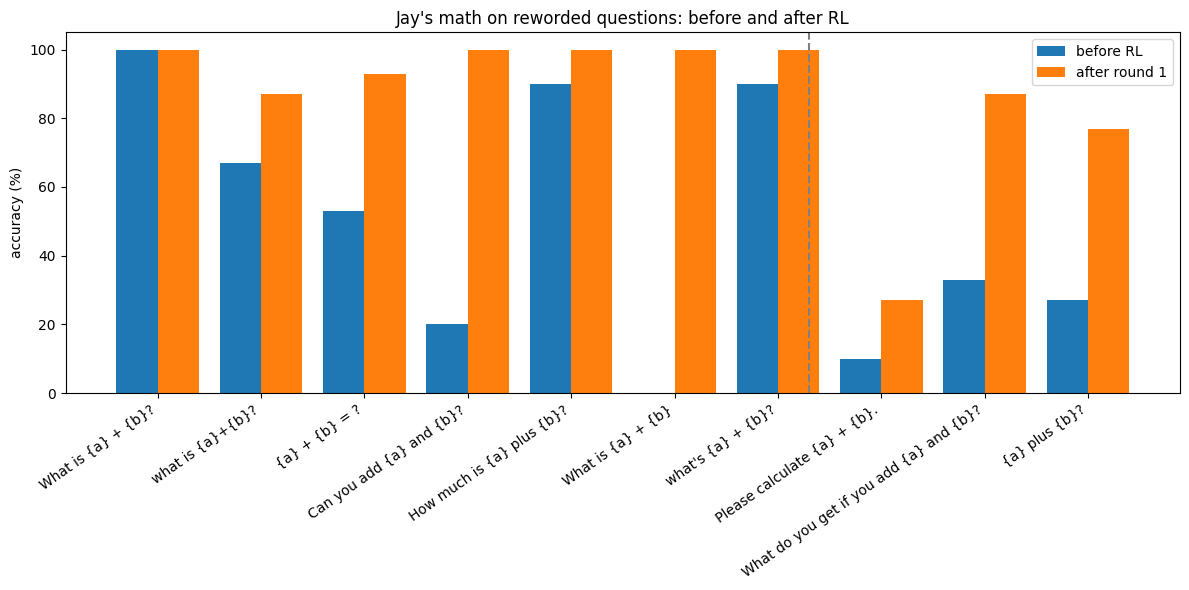

In [15]:
# STEP 43: THE CHART (BEFORE VS AFTER)
import numpy as np
import matplotlib.pyplot as plt

templates = [CONTROL_TEMPLATE] + TRAIN_TEMPLATES + TEST_TEMPLATES
x = np.arange(len(templates))
width = 0.8 / len(rl_history)

plt.figure(figsize=(12, 6))
for i, scores in enumerate(rl_history):
  label = "before RL" if i == 0 else ("after RL" if len(rl_history) == 2 else f"after round {i}")
  # shift each group of bars by i * width so they sit side by side
  plt.bar(x + i * width, [scores[t] * 100 for t in templates], width, label=label)
plt.xticks(x + width * (len(rl_history) - 1) / 2, templates, rotation=35, ha="right")
# dashed line between the practised templates and the never-seen ones
plt.axvline(len(TRAIN_TEMPLATES) + 0.5, color="gray", linestyle="--")
plt.ylabel("accuracy (%)")
plt.title("Jay's math on reworded questions: before and after RL")
plt.legend()
plt.tight_layout()
plt.show()

## Step 44: Did Jay forget anything?

Check that identity, stories and "I don't know" still work after RL.

In [19]:
# STEP 44: DID JAY FORGET ANYTHING?
for q in ["Who are you?", "Tell me a stoy about a cat.", "What is te cpital of Japan?", "What is 7 + 8?"]:
  print("USER :", q)
  print("JAY  :", chat(q, temperature=0.3)[:200].replace("\n", " "), "\n")

USER : Who are you?
JAY  : I am Jay, a very small language model. Josue built and trained me from scratch in a notebook. I am good at telling short stories for kids, but I don't know much about the world. 

USER : Tell me a stoy about a cat.
JAY  : Once upon a time, there was a little girl named Lily. She lived in a big house with a large yard. One day, she was sitting on the porch with her mommy. Lily said, "Mommy, I'm thirsty. Can I have some  

USER : What is te cpital of Japan?
JAY  : I'm sorry, I don't know that. I only know how to tell short stories for kids and do small additions. 

USER : What is 7 + 8?
JAY  : 7 + 8: start at 7 and count up 8 times: (1/8) 8, (2/8) 9, (3/8) 10, (4/8) 11, (5/8) 12, (6/8) 13, (7/8) 14, (8/8) 15. So 7 + 8 = 15. 



## Step 45: Can RL teach new story topics?

Load Jay v3 (after RL) and measure how often Jay's stories mention the requested topic, for practised topics and held-back ones.

In [22]:
# STEP 45: CAN RL TEACH JAY NEW STORY TOPICS?  (part 1: how often does he already succeed?)
import re, time

STORY_TEMPLATE = "Tell me a story about a {topic}."
TRAIN_TOPICS = ["pirate", "robot", "strawberry", "rocket"]   # Jay PRACTICES these
TEST_TOPICS  = ["wizard", "shark", "castle", "monster"]      # held back: do they get better too?

def topic_reward(reply, topic):
  # 1 if the story mentions the topic as a whole word (plural ok: pirate -> pirates), else 0
  return int(re.search(rf"\b{topic}", reply.lower()) is not None)

def story_scores(topics, k=8, label=""):
  print(f"\n==== {label} ====")
  scores = {}
  for tp in topics:
    t0 = time.time()
    replies = sample_k(STORY_TEMPLATE.format(topic=tp), k=k, temperature=1.0)
    scores[tp] = sum(topic_reward(r, tp) for r in replies) / k
    print(f"{tp:12} | {scores[tp]*100:4.0f}% of {k} tries mention it ({time.time()-t0:.0f}s)")
  return scores

# Start from Jay v3, the model saved after the RL loop in STEP 42
jay_v3 = GPT().to(device)
jay_v3.load_state_dict(torch.load(f"{SAVE_DIR}/chat_model_v3.pt", map_location=device))
model = jay_v3
story_before = story_scores(TRAIN_TOPICS + TEST_TOPICS, k=8, label="BEFORE story-RL")


==== BEFORE story-RL ====
pirate       |    0% of 8 tries mention it (66s)
robot        |    0% of 8 tries mention it (59s)
strawberry   |    0% of 8 tries mention it (65s)
rocket       |    0% of 8 tries mention it (64s)
wizard       |    0% of 8 tries mention it (65s)
shark        |    0% of 8 tries mention it (64s)
castle       |    0% of 8 tries mention it (65s)
monster      |    0% of 8 tries mention it (64s)
